In [2]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/featured_data.csv", parse_dates=["StartDatetime"])
df = df.sort_values("StartDatetime").reset_index(drop=True)

cat_cols = ["ChargerCompany", "ChargerType", "Location", "TimeOfDay"]
num_cols = ["Hour", "Day", "Month", "DayOfWeek", "IsWeekend",
            "User_PrevSessions", "User_AvgPastDemand",
            "Charger_PrevSessions", "Charger_AvgPastDemand", "IsNewUser"]
X = df[cat_cols + num_cols]
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]

reg_pipe = joblib.load("../models/best_regression_model.pkl")   # LightGBM
prep = reg_pipe.named_steps["prep"]
model = reg_pipe.named_steps["model"]

feat_names = prep.get_feature_names_out()
feat_names = [n.split("__", 1)[1] for n in feat_names]

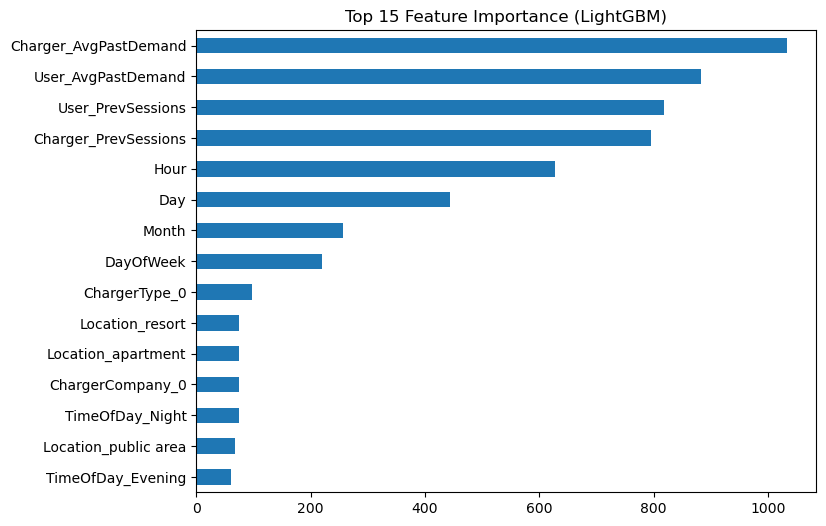

In [3]:
imp = pd.Series(model.feature_importances_, index=feat_names).sort_values(ascending=False)
imp.head(15).sort_values().plot.barh(figsize=(8, 6), title="Top 15 Feature Importance (LightGBM)")
plt.show()

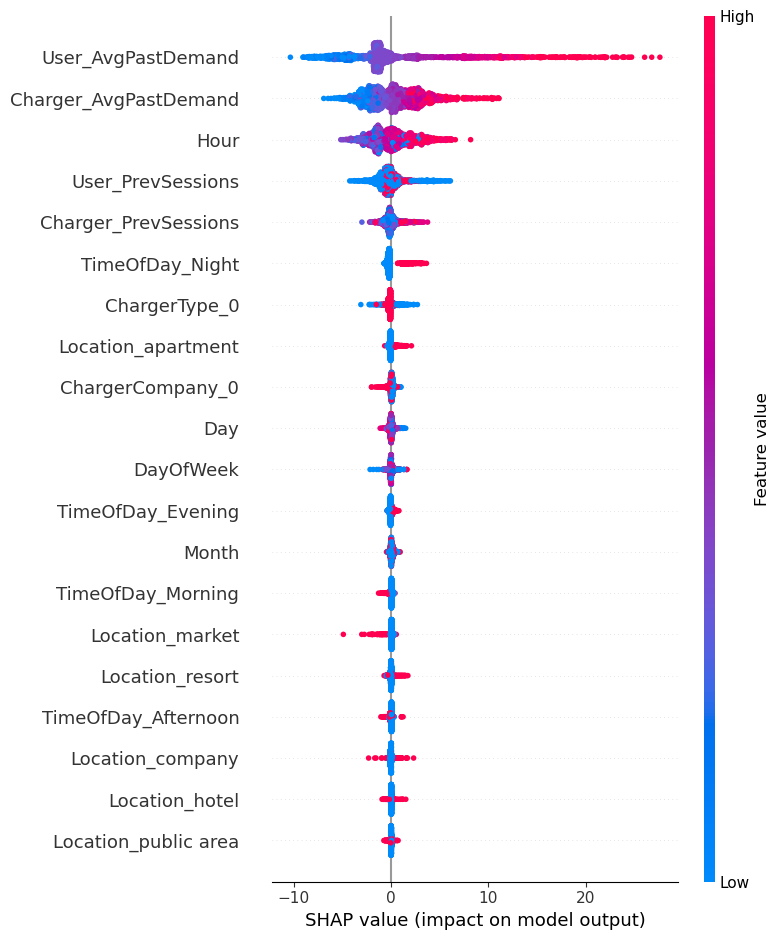

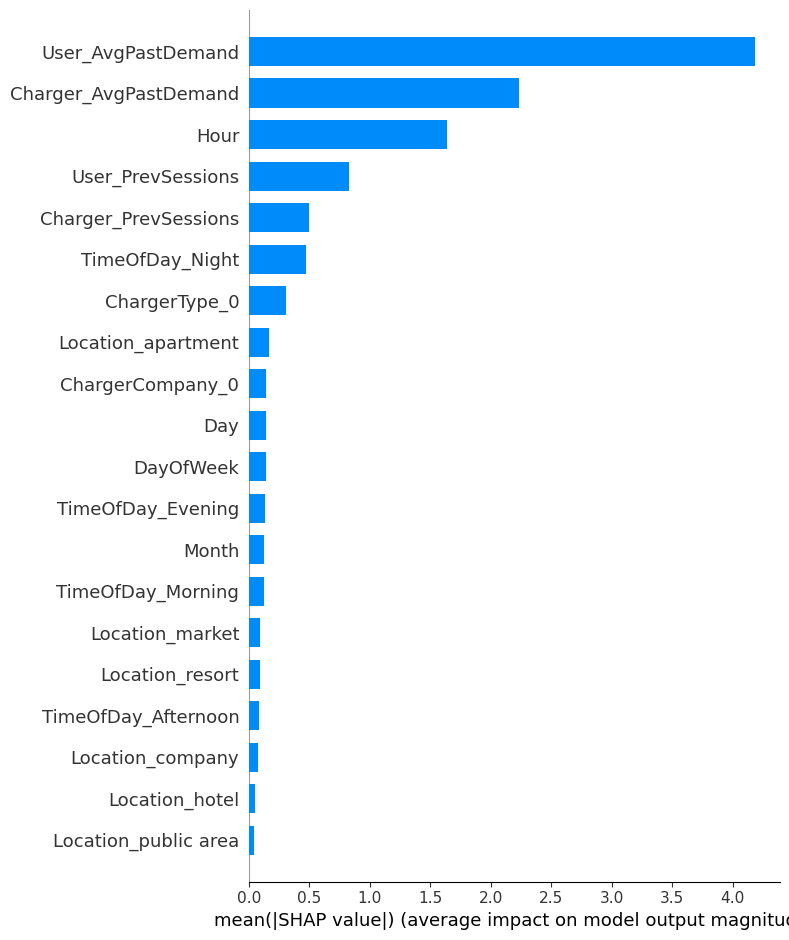

In [4]:
import shap

X_sample = X_test.sample(2000, random_state=42)
X_sample_t = prep.transform(X_sample)
if hasattr(X_sample_t, "toarray"):
    X_sample_t = X_sample_t.toarray()

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample_t)

shap.summary_plot(shap_values, X_sample_t, feature_names=feat_names, show=False)
plt.tight_layout(); plt.show()

shap.summary_plot(shap_values, X_sample_t, feature_names=feat_names, plot_type="bar", show=False)
plt.tight_layout(); plt.show()

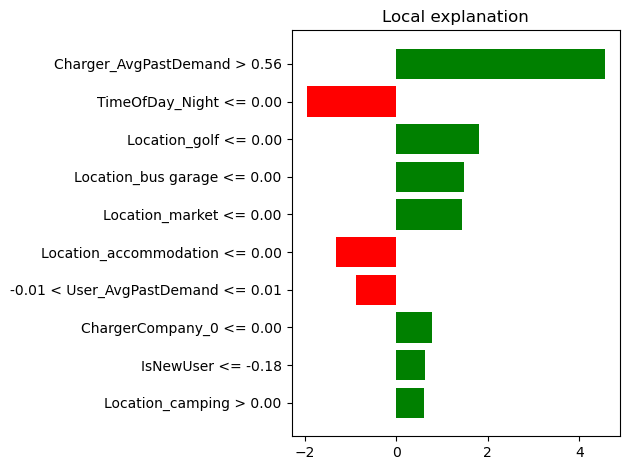

Actual features:
 ChargerCompany                   1
ChargerType                      0
Location                   camping
TimeOfDay                  Evening
Hour                            18
Day                             31
Month                            7
DayOfWeek                        6
IsWeekend                        1
User_PrevSessions            26259
User_AvgPastDemand        16.53473
Charger_PrevSessions           274
Charger_AvgPastDemand    27.053358
IsNewUser                        0
Name: 58443, dtype: object


In [5]:
from lime.lime_tabular import LimeTabularExplainer

X_train_t = prep.transform(X_train.sample(5000, random_state=42))
if hasattr(X_train_t, "toarray"):
    X_train_t = X_train_t.toarray()

lime_exp = LimeTabularExplainer(X_train_t, feature_names=feat_names,
                                mode="regression", random_state=42)

row = X_sample_t[0]
exp = lime_exp.explain_instance(row, model.predict, num_features=10)
exp.as_pyplot_figure(); plt.tight_layout(); plt.show()
print("Actual features:\n", X_sample.iloc[0])

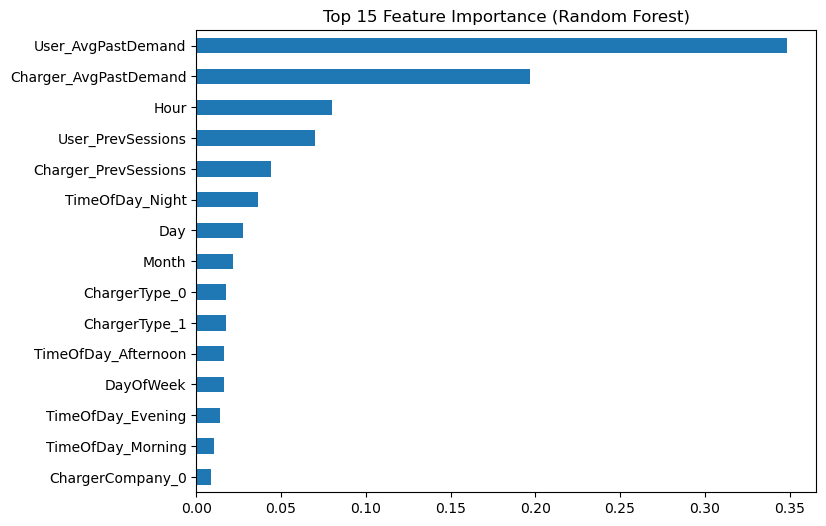

In [6]:
clf_pipe = joblib.load("../models/best_classification_model.pkl")
clf_imp = pd.Series(clf_pipe.named_steps["model"].feature_importances_,
                    index=feat_names).sort_values(ascending=False)
clf_imp.head(15).sort_values().plot.barh(figsize=(8, 6), title="Top 15 Feature Importance (Random Forest)")
plt.show()

In [9]:
import os
os.makedirs("../results", exist_ok=True)

imp.to_csv("../results/reg_feature_importance.csv", header=["importance"])
clf_imp.to_csv("../results/clf_feature_importance.csv", header=["importance"])

shap.summary_plot(shap_values, X_sample_t, feature_names=feat_names, show=False)
plt.savefig("../results/shap_summary.png", bbox_inches="tight", dpi=150); plt.close()

shap.summary_plot(shap_values, X_sample_t, feature_names=feat_names, plot_type="bar", show=False)
plt.savefig("../results/shap_bar.png", bbox_inches="tight", dpi=150); plt.close()

exp.save_to_file("../results/lime_example.html")

In [10]:
lime_df = pd.DataFrame(exp.as_list(), columns=["Condition", "Effect"])
lime_df["Predicted"] = float(exp.predicted_value)
lime_df.to_csv("../results/lime_example.csv", index=False)

pd.DataFrame({"Feature": X_sample.iloc[0].index,
              "Value": X_sample.iloc[0].astype(str).values}
             ).to_csv("../results/lime_session.csv", index=False)
print("saved")

saved
